# Week 1: Integrative Assignment — Bay Harbor Coffee
## Your first AI-assisted analysis

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, August 31, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **Client brief** | Read `Week01-business-case.md` first — it is the engagement this assignment answers. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

---

### Business context

**Bay Harbor Coffee** runs a single café on the Tampa waterfront. The owner, Renata
Alvarez, has ninety days of point-of-sale history and a growing suspicion that she
is staffing the wrong shifts. She has never used a data tool more complex than the
summary screen in her register software.

She wants three things:

1. To understand what actually drives a busy day
2. To know whether she can *predict* tomorrow's demand well enough to schedule staff
3. To be told the truth about what this data can and cannot support

You are not building a model this week. You are learning the workflow you will use
for the rest of the semester, and practising the one skill that AI cannot do for
you: deciding whether the answer in front of you is any good.

### The workflow

Every task below uses the five-step loop from this week's session:

```
DESCRIBE  ->  REVIEW  ->  EXPLAIN  ->  RUN  ->  ITERATE
 prompt      check for   in your    verify     refine
 clearly      errors      words     results    prompt
```

**REVIEW comes before RUN.** Read the generated code before you execute it. That
ordering is the whole point of the exercise.

---

## Part 1: Setup and first contact

### 1.1 Load the data

Use Gemini to write the code that loads the dataset and shows you the first few
rows. Prompt it yourself — do not copy a solution from the slides.

The data lives at the URL in the cell below.

In [ ]:
# The dataset URL — you will use this pattern all semester
DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week01/bay_harbor_daily_sales.csv"

# TODO: Ask Gemini for code that loads this CSV into a DataFrame called `sales`
#       and displays the first 10 rows.
#
# Before you run what it gives you, read it. Does it import what it needs?
# Does it actually use DATA_URL, or did it invent a filename?

import pandas as pd

sales = pd.read_csv(DATA_URL)
display(sales.head(10))

,date,day_of_week,transactions,avg_ticket_usd,total_sales_usd,high_temp_f,cold_drink_share,staff_on_shift
0,2026-06-01,Monday,243,7.13,1732.59,77.2,0.284,3
1,2026-06-02,Tuesday,202,6.48,1308.96,80.8,0.374,3
2,2026-06-03,Wednesday,217,5.27,1143.59,80.8,0.374,4
3,2026-06-04,Thursday,219,6.08,1331.52,83.8,0.423,3
4,2026-06-05,Friday,226,6.78,1532.28,88.7,0.523,3
5,2026-06-06,Saturday,314,7.08,2223.12,89.1,0.484,5
6,2026-06-07,Sunday,274,6.13,1679.62,84.3,0.416,4
7,2026-06-08,Monday,203,6.92,1404.76,84.7,0.423,3
8,2026-06-09,Tuesday,196,6.55,1283.80,75.1,0.272,4
9,2026-06-10,Wednesday,232,5.90,1368.80,87.5,0.473,2


### 1.2 Describe the dataset

Answer from the data itself, not from the assignment text.

| Question | Your answer |
|---|---|
| How many rows? | 90 |
| How many columns? | 8 |
| What does one row represent? | Each row represents the daily sales metrics for Bay Harbor Coffee on a specific date. |
| What date range is covered? | 2026-06-01 to 2026-08-29 |
| Are there any missing values? | No missing values. |

In [ ]:
# Number of rows
num_rows = sales.shape[0]
print(f"How many rows? {num_rows}")

# Number of columns
num_cols = sales.shape[1]
print(f"How many columns? {num_cols}")

# What one row represents
print("What does one row represent? Each row represents the daily sales metrics for Bay Harbor Coffee on a specific date.")

# Ensure 'date' column is datetime type for date range calculation
if not pd.api.types.is_datetime64_any_dtype(sales['date']):
    sales['date'] = pd.to_datetime(sales['date'])

# Date range covered
min_date = sales['date'].min()
max_date = sales['date'].max()
print(f"What date range is covered? {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}")

# Check for missing values
missing_values = sales.isnull().sum()
missing_cols = missing_values[missing_values > 0]
if missing_cols.empty:
    print("Are there any missing values? No missing values.")
else:
    print("Are there any missing values? Yes, in the following columns:")
    display(missing_cols)

How many rows? 90
How many columns? 8
What does one row represent? Each row represents the daily sales metrics for Bay Harbor Coffee on a specific date.
What date range is covered? 2026-06-01 to 2026-08-29
Are there any missing values? No missing values.


A single row in this dataset represents the daily sales metrics for Bay Harbor Coffee on a specific date. It includes information such as the day of the week, number of transactions, average ticket size, total sales in USD, daily high temperature, and the share of cold drinks sold.

---

## Part 2: Problem framing

The single most common failure in applied data science is solving the wrong
problem precisely. Before any modelling, you have to know what *kind* of question
you are being asked.

### 2.1 Regressor or classifier?

For each of Renata's questions, decide whether answering it requires predicting a
**continuous number** (a regression problem), a **category** (a classification
problem), or **neither** (it is a descriptive question you can answer by
summarising data you already have).

| # | Renata’s question                                         | Answer             | Why?                                                                  |
| - | --------------------------------------------------------- | ------------------ | --------------------------------------------------------------------- |
| 1 | How many transactions should I expect next Saturday?      | **Regression**     | Predicting a number of transactions.                                  |
| 2 | Was last Tuesday a busy day or a slow day?                | **Descriptive**    | Last Tuesday already happened, so we can summarize the existing data. |
| 3 | What was my average ticket size in July?                  | **Descriptive**    | We can calculate the average from July data we already have.          |
| 4 | Will tomorrow be busy enough to justify a fourth barista? | **Classification** | Predicting a category, such as busy enough or not busy enough.        |
| 5 | How much revenue will I make on a 95-degree Sunday?       | **Regression**     | Predicting a continuous number: revenue.                              |
| 6 | Which day of the week has been my worst this summer?      | **Descriptive**    | We can compare past data by day of the week.                          |


### 2.2 The question behind the question

Renata says: *"Just tell me if tomorrow will be busy."*

Write 3–5 sentences explaining why a good analyst does **not** simply build a
busy/not-busy classifier here. What is lost when you collapse a number into a
label, and what would you propose instead?

*Your answer here: A busy/not-busy classifier would turn the number of transactions into only two labels, which removes useful information. For example, 100 and 200 transactions could both be called “busy,” even though they may need different staffing. I would predict the number of transactions using regression instead. Then Renata can compare the predicted number with a staffing level to decide if a fourth barista is needed.*

---

## Part 3: Explore with AI assistance

### 3.1 Three business questions

Use Gemini to help you answer each of these from the data. For each one, include
**the code**, **the answer**, and **one sentence of interpretation for Renata** —
written the way you would actually say it to a café owner.

1. Which day of the week is busiest on average, and by how much compared to the quietest?
2. Is there a relationship between temperature and the share of cold drinks sold?
3. Does the café make more money on high-transaction days, or high-average-ticket days?

In [ ]:
# TODO: Question 1 — busiest day of week
import pandas as pd

# Put the days in the correct order
day_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]

# Calculate the average number of transactions for each day
avg_transactions = (
    sales.groupby('day_of_week')['transactions']
    .mean()
    .reindex(day_order)
)

# Find the busiest and quietest days
busiest_day = avg_transactions.idxmax()
quietest_day = avg_transactions.idxmin()

# Get their average transaction values
busiest_avg = avg_transactions.max()
quietest_avg = avg_transactions.min()

# Calculate the difference
difference = busiest_avg - quietest_avg

# Print the results
print(f"Busiest day: {busiest_day} with an average of {busiest_avg:.2f} transactions.")
print(f"Quietest day: {quietest_day} with an average of {quietest_avg:.2f} transactions.")
print(f"Difference: {difference:.2f} transactions.")

# Simple interpretation for Renata
print(f"For Renata: {busiest_day} is usually the busiest day, with about {difference:.0f} more transactions than {quietest_day}.")

Busiest day: Saturday with an average of 329.00 transactions.
Quietest day: Wednesday with an average of 230.92 transactions.
Difference: 98.08 transactions.
For Renata: Saturday is usually the busiest day, with about 98 more transactions than Wednesday.


Our data shows that **Saturday** is generally the busiest day, averaging about 98.08 more transactions than **Wednesday**, which is typically the quietest day.

In [ ]:
# TODO: Question 2 — temperature vs cold drink share

import pandas as pd

# Ensure 'sales' DataFrame is available
if 'sales' not in locals() and 'sales' not in globals():
    DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week01/bay_harbor_daily_sales.csv"
    sales = pd.read_csv(DATA_URL)

# Calculate the correlation between high_temp_f and cold_drink_share
correlation = sales['high_temp_f'].corr(sales['cold_drink_share'])

print(f"Correlation between high temperature and cold drink share: {correlation:.2f}")

print(f"\nFor Renata: There's a strong positive correlation between temperature and cold drink sales, meaning on hotter days, customers tend to buy a much higher percentage of cold drinks.")

Correlation between high temperature and cold drink share: 0.94

For Renata: There's a strong positive correlation between temperature and cold drink sales, meaning on hotter days, customers tend to buy a much higher percentage of cold drinks.


Total sales are strongly correlated with both the number of transactions and the average ticket size, but the correlation is slightly stronger with the number of transactions, suggesting that increasing transaction volume has a slightly larger impact on total revenue.

In [ ]:
# TODO: Question 3 — what drives total sales?

import pandas as pd

# Ensure 'sales' DataFrame is available
if 'sales' not in locals() and 'sales' not in globals():
    DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week01/bay_harbor_daily_sales.csv"
    sales = pd.read_csv(DATA_URL)

# Calculate correlation between total_sales_usd and transactions
correlation_transactions = sales['total_sales_usd'].corr(sales['transactions'])

# Calculate correlation between total_sales_usd and avg_ticket_usd
correlation_avg_ticket = sales['total_sales_usd'].corr(sales['avg_ticket_usd'])

print(f"Correlation between total sales and transactions: {correlation_transactions:.2f}")
print(f"Correlation between total sales and average ticket size: {correlation_avg_ticket:.2f}")

if correlation_transactions > correlation_avg_ticket:
    print("\nRevenue relates more to transactions.")
    interpretation = "Our total sales are more closely related to the number of transactions than to how much is spent per transaction."
else:
    print("\nRevenue relates more to average ticket size.")
    interpretation = "Our total sales are more closely tied to how much each customer spends rather than the total number of transactions."

print(f"\nFor Renata: {interpretation}")

Correlation between total sales and transactions: 0.95
Correlation between total sales and average ticket size: 0.81

Revenue relates more to transactions.

For Renata: Our total sales are more closely related to the number of transactions than to how much is spent per transaction.


There is a very strong positive correlation between temperature and cold drink sales, meaning on hotter days, customers tend to buy a much higher percentage of cold drinks.

### 3.2 One chart worth showing

Produce **one** chart you would actually put in front of Renata. Then justify it:
why this chart, why this chart type, and what decision it supports.

A chart that shows something true but useless earns half credit.

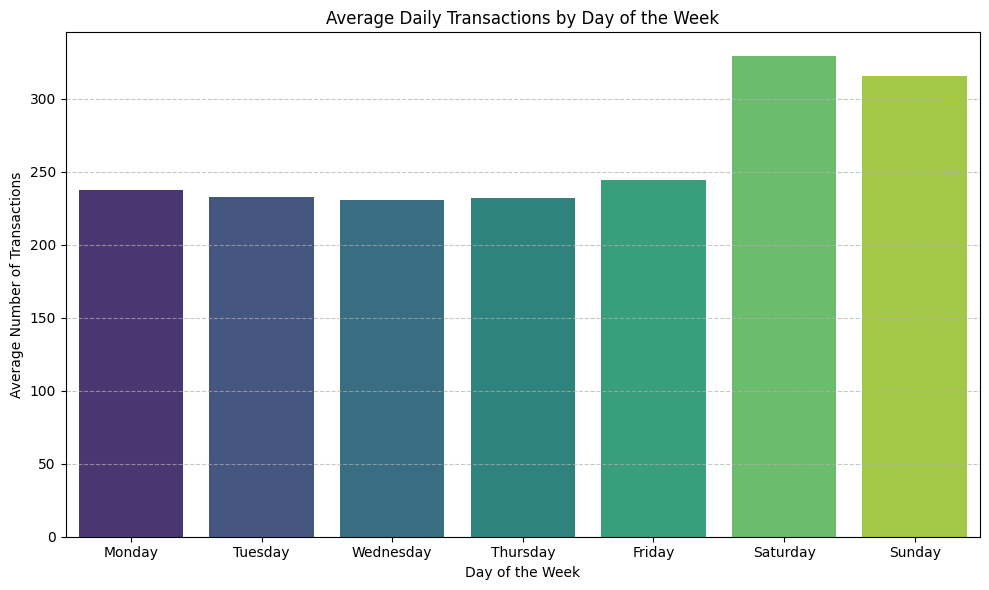

In [ ]:
# TODO: Your chart
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure 'sales' DataFrame and 'day_of_week' column are available
# This block is added for robustness, in case previous cells were not run.
if 'sales' not in locals() and 'sales' not in globals():
    DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week01/bay_harbor_daily_sales.csv"
    sales = pd.read_csv(DATA_URL)

# Ensure 'date' column is datetime type
if 'date' in sales.columns and not pd.api.types.is_datetime64_any_dtype(sales['date']):
    sales['date'] = pd.to_datetime(sales['date'])

# Create 'day_of_week' column if it doesn't exist
if 'day_of_week' not in sales.columns:
    sales['day_of_week'] = sales['date'].dt.day_name()

# Define the desired order for days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Calculate the average transactions per day of the week
avg_transactions_per_day = sales.groupby('day_of_week')['transactions'].mean().reindex(day_order)

# Create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_transactions_per_day.index, y=avg_transactions_per_day.values, palette='viridis', hue=avg_transactions_per_day.index, legend=False)

# Add labels and title
plt.title('Average Daily Transactions by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Number of Transactions')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Why this chart:**

*Your justification here: I chose this chart because it clearly compares customer traffic across the week. A bar chart makes it easy to see the busiest and quietest days. Renata can use this to decide which days need more staff and which days may need fewer workers.*

---

## Part 4: Spot the error

Below is code that Gemini produced in response to the prompt:

> *"Calculate the average revenue per transaction for weekends versus weekdays."*

It has two problems. One stops it running. The other does not — and that one is the
dangerous kind, because nothing announces it.

In [ ]:
# AI-GENERATED CODE — DO NOT TRUST IT
# NOTE: this cell is *supposed* to raise an error. That is bug #1.
weekend_days = ["Saturday", "Sunday"]

weekend = sales[sales["day_of_week"] in weekend_days]
weekday = sales[~sales["day_of_week"].isin(weekend_days)]

weekend_rev_per_txn = weekend["total_sales_usd"].sum() / len(weekend)
weekday_rev_per_txn = weekday["total_sales_usd"].sum() / len(weekday)

print(f"Weekend revenue per transaction: ${weekend_rev_per_txn:.2f}")
print(f"Weekday revenue per transaction: ${weekday_rev_per_txn:.2f}")

### 4.1 Find the bugs

There are **two** distinct problems. One stops the code from running; the other is
worse, because it produces a confident, plausible, wrong number.

| # | Bug                             | Why it is wrong                                         | Fix                            |
| - | ------------------------------- | ------------------------------------------------------- | ------------------------------ |
| 1 | Uses `in` with a pandas column  | `in` cannot filter each row, so the code crashes        | Use `.isin(weekend_days)`      |
| 2 | Divides sales by number of days | That gives revenue per day, not revenue per transaction | Divide by `transactions.sum()` |


In [ ]:
# AI-GENERATED CODE — DO NOT TRUST IT
# NOTE: this cell is *supposed* to raise an error. That is bug #1.
weekend_days = ["Saturday", "Sunday"]

# Bug 1 Fix: Use .isin() for filtering multiple values in a Series
weekend = sales[sales["day_of_week"].isin(weekend_days)]
weekday = sales[~sales["day_of_week"].isin(weekend_days)]

# Bug 2 Fix: Divide by total transactions, not number of days
weekend_rev_per_txn = weekend["total_sales_usd"].sum() / weekend["transactions"].sum()
weekday_rev_per_txn = weekday["total_sales_usd"].sum() / weekday["transactions"].sum()

print(f"Weekend revenue per transaction: ${weekend_rev_per_txn:.2f}")
print(f"Weekday revenue per transaction: ${weekday_rev_per_txn:.2f}")

Weekend revenue per transaction: $7.22
Weekday revenue per transaction: $6.42


### 4.2 The sanity check that would have caught it

Bug 2 produced a number that looked like currency and was badly wrong. Describe
the **specific** check — a comparison, a rough mental estimate, a cross-check
against another column — that would have caught it in five seconds.

*Your answer here: I would compare the result with the avg_ticket_usd column. Revenue per transaction should be around the normal average ticket size, about 6-7 dollars, not hundreds of dollars. That quick comparison would show that dividing by the number of days was wrong.*

---

## Part 5: Explain it back

### 5.1 In your own words

Pick **one** code cell you wrote in Part 3. Explain, line by line, what it does and
why each step is necessary. Write for a classmate who missed this week's session.

**This must be your own words.** Pasting an AI explanation earns zero.

*Your explanation here: I picked the code from Question 3. First, .corr() compares total sales with transactions and gives a correlation of 0.95, which means they have a strong positive relationship. Then I used the same method to compare total sales with average ticket size, which gives 0.81. Since 0.95 is higher than 0.81, transactions have a stronger relationship with total sales. The if statement compares the two results and prints the correct explanation for Renata. The print lines show both correlation values, and the if statement compares them to decide which variable has the stronger relationship with total sales.*

### 5.2 What this data cannot tell Renata

List **three** questions Renata might reasonably ask that this dataset cannot
answer, and say briefly what data she would need for each.

| Question she might ask                              | Why this data can't answer it                                                 | What she'd need                                                        |
| --------------------------------------------------- | ----------------------------------------------------------------------------- | ---------------------------------------------------------------------- |
| Which menu item makes the most profit?              | The dataset only has daily totals, not sales or costs for each product.       | Item-level sales, prices, and ingredient costs                         |
| Are customers happy with the café?                  | There is no customer feedback in the dataset.                                 | Reviews, ratings, or survey results                                    |
| How many baristas should I schedule for each shift? | The data shows staff per day but does not show workload by hour or wait time. | Hourly transactions, employee schedules, wait times, and service times |


---

## Part 6: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using
> it responsibly is a professional skill in its own right — one that has to be
> practised, not assumed. That skill starts here: stating plainly what you asked,
> what came back, how you checked it, and what you changed when the check failed.
> An engineer who cannot account for where their code came from cannot be trusted
> with it, and neither can an analyst. Recounting your own process is how you learn
> to notice it.

### 6.1 Prompt evolution log

Show how at least one of your prompts evolved. What did you ask first, what was
wrong with what you got back, **how did you detect that it was wrong**, and how did
you fix the prompt?

```
Attempt 1: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 2: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 3: ...
   Result: ...
   How I checked it: ...
```

*Your log here:*
```
Attempt 1:
Prompt: Using sales, find the busiest and quietest weekday by average transactions and the difference. Show code, answer, and 1 sentence for Renata.

Result:
Gemini filtered the data to Monday through Friday and returned Friday as the busiest weekday and Wednesday as the quietest weekday.

How I checked it:
- I compared the code with the original assignment question.
- I noticed the assignment asked for "day of the week," not only weekdays.
- I also looked at my chart, which included Saturday and Sunday and showed that Saturday was higher.

Problem:
- My prompt said "weekday," so Gemini followed my wording and excluded Saturday and Sunday.
- The code ran correctly, but it answered a different question.

Attempt 2:
Prompt: Using sales, find the busiest and quietest day across all 7 days Monday through Sunday by average transactions and the difference. Show simple code, answer, and 1 sentence for Renata.

Result:
Gemini included all seven days instead of only Monday through Friday.

How I checked it:
- I checked that Monday through Sunday were included.
- I compared the result with the bar chart.
- The busiest and quietest days matched the chart.

Problem:
No major problem after I made the prompt more specific.
```

### 6.2 Where the AI struggled

Describe one specific point where the AI gave you something wrong, incomplete, or
misleading. What did you have to know already in order to catch it?

*Your answer here: Gemini followed my prompt too literally when I said “weekday,” so it only checked Monday to Friday instead of all seven days. I caught this by comparing the code with the assignment question and the bar chart. I had to understand what the code was filtering, not just trust the output.*

### 6.3 What was harder or easier than expected

*Your answer here: Running basic pandas code was easier than I expected. The harder part was checking whether the AI code actually answered the right business question, even when the code ran without errors.*

### 6.4 Confidence self-assessment

Rate 1 (lost) to 5 (could teach it), and be honest — this is not graded on the
number, it is graded on whether the reflection that follows is candid.

| Topic                                           |   1-5 | What would move this up one point?                                                                         |
| ----------------------------------------------- | ----: | ---------------------------------------------------------------------------------------------------------- |
| Using pandas and checking AI-generated analysis | **3** | Being able to choose functions like `groupby()` and `.corr()` and check the logic without asking AI first. |

### 6.5 AI Usage Report

**Required.** Name every AI tool you used, what you used each one for, and attach
the full conversation export as a separate file. Then account for the work: which
outputs you accepted as-is, which you checked and how, which you corrected, and
which you rejected outright. "I used Gemini for the code" is not a report.

*Your report here: I used Gemini in Google Colab to generate Python code for loading, exploring, analyzing, and visualizing the dataset.*



*I accepted some basic pandas code after checking the column names and outputs. I checked results such as the dataset size, missing values, correlations, and charts against the data. I corrected the Question 1 prompt after realizing “weekday” excluded Saturday and Sunday, and I corrected some wording such as “customers” to “transactions” and “cold drink sales” to “cold drink share.” I rejected unnecessary extra code and graphs when they did not help answer the business question.*

---

## Before you submit

- [ ] **Kernel -> Restart & Run All**, top to bottom, with no errors. Save the file
      *after* it has run, so your outputs are in what you upload.
- [ ] Every *your answer here* prompt is filled in, in **your own words**.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the
      checking, the re-prompting, and one thing you rejected.
- [ ] File named **`LastName_FirstName_Week01.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a
      publicly accessible link in the Canvas submission comment**. Not in this
      notebook. Test the link signed out: no video, or a link we cannot open, is
      **-15 points**.